### Notebook 04: Support Vector Machine (Pembanding)

#### 1. Persiapan

##### 1.1 Pustaka

In [1]:
import importlib
import json
import platform
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn
from sklearn.exceptions import ConvergenceWarning

print("Python       :", platform.python_version())
print("NumPy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)

Python       : 3.10.6
NumPy        : 1.26.4
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.2


##### 1.2 Konfigurasi

In [2]:
PREFIX = "04_svm"
MODEL_LABEL = "SVM"


def find_ml_dir(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "src" / "models.py").exists():
            return folder
        if (folder / "ml" / "src" / "models.py").exists():
            return folder / "ml"
    raise FileNotFoundError("Folder ml/ tidak ditemukan. Buka notebook ini dari dalam repo Nutrify.")


ML_DIR = find_ml_dir(Path.cwd().resolve())
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import evaluation as ev, models

importlib.reload(ev)
importlib.reload(models)

SEED = 42
LEARNING_FRACTIONS = (0.2, 0.4, 0.6, 0.8, 1.0)
PERMUTATION_REPEATS = 30
N_BOOTSTRAP = 2000
GALLERY_SIZE = 12
TRAIN_TIMING_REPEATS = 10
PREDICT_TIMING_REPEATS = 5
C_VALUES = (0.1, 1, 10, 100)
GAMMA_VALUES = (0.001, 0.01, 0.1, 1)
SVM_MAX_ITER = 5_000_000
KERNELS = ("linear", "rbf", "poly")
KERNEL_LABEL = {"linear": "Linear", "rbf": "RBF", "poly": "Polinomial (derajat 3)"}

RAW_DIR = ML_DIR / "data" / "raw"
FIGURES_DIR = ML_DIR / "reports" / "figures"
TABLES_DIR = ML_DIR / "reports" / "tables"
RESULTS_DIR = ML_DIR / "reports" / "results"
MODELS_DIR = ML_DIR / "models" / "candidates"
for folder in (FIGURES_DIR, TABLES_DIR, RESULTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ev.CLASSES
CLASS_LABEL_ID = ev.CLASS_LABEL_ID
CLASS_COLORS = ev.CLASS_COLORS
FEATURE_SETS = ev.FEATURE_SETS
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})


def save_figure(fig, name: str) -> None:
    fig.savefig(FIGURES_DIR / f"{PREFIX}_{name}", bbox_inches="tight")


def save_table(table, name: str, **kwargs) -> None:
    table.to_csv(TABLES_DIR / f"{PREFIX}_{name}.csv", **kwargs)


def as_float(value):
    return None if value is None or (isinstance(value, float) and np.isnan(value)) else float(value)


print("Folder ml/ :", ML_DIR)

Folder ml/ : D:\LARAGON\www\nutrify\ml


##### 1.3 Perangkat keras

In [3]:
HARDWARE = {
    "Laptop": "Lenovo LOQ 15IAX9",
    "CPU": "Intel Core i5-12450HX, 2.40 GHz",
    "RAM": "12 GB DDR5 (11,7 GB dapat dipakai)",
    "GPU": "Tidak dipakai (RTX 3050 tersedia, scikit-learn berjalan di CPU)",
    "Sistem": "Windows 11 Home, 64-bit",
}
hardware_table = pd.Series(
    {
        **HARDWARE,
        "Python": platform.python_version(),
        "Inti logis CPU": psutil.cpu_count(logical=True),
        "RAM terdeteksi (GB)": round(psutil.virtual_memory().total / 1024 ** 3, 1),
    },
    name="nilai",
).to_frame()
display(hardware_table)

,nilai
Laptop,Lenovo LOQ 15IAX9
CPU,"Intel Core i5-12450HX, 2.40 GHz"
RAM,"12 GB DDR5 (11,7 GB dapat dipakai)"
GPU,"Tidak dipakai (RTX 3050 tersedia, scikit-learn..."
Sistem,"Windows 11 Home, 64-bit"
Python,3.10.6
Inti logis CPU,12
RAM terdeteksi (GB),11.7


#### 2. Data

##### 2.1 Data latih dan himpunan fitur

In [4]:
train = ev.load_partition(ML_DIR, "train")
assert set(train["origin"]) == {"roboflow"}
assert train["image_id"].is_unique

SELECTED_SET = ev.load_selected_feature_set(ML_DIR)
SELECTED_FEATURES = FEATURE_SETS[SELECTED_SET]

data_summary = train.groupby("label").agg(berkas=("image_id", "size"), foto_sumber=("source_group", "nunique")).reindex(CLASSES)
data_summary.index = [CLASS_LABEL_ID[c] for c in data_summary.index]
data_summary.loc["Total"] = data_summary.sum()
save_table(data_summary, "train_summary")
display(data_summary)

print("Himpunan fitur dari notebook 03 :", SELECTED_SET, SELECTED_FEATURES)

,berkas,foto_sumber
Normal,92,57
Defisiensi N,70,16
Defisiensi Fe,142,35
Total,304,108


Himpunan fitur dari notebook 03 : A1 ['Mean_R', 'Mean_G', 'Mean_B']


#### 3. Landasan Matematis SVM

##### 3.1 Pembakuan fitur

$$
z_j = \frac{x_j - \mu_j}{\sigma_j}
$$

dengan $\mu_j$ dan $\sigma_j$ dihitung hanya dari data latih pada setiap lipatan.

##### 3.2 Margin lunak (bentuk primal)

$$
\min_{w,\, b,\, \xi} \ \frac{1}{2}\lVert w \rVert^{2} + C \sum_{i=1}^{n} w_{y_i}\, \xi_i
\qquad \text{dengan} \qquad
y_i \left( w^{\top}\phi(z_i) + b \right) \ge 1 - \xi_i, \quad \xi_i \ge 0
$$

##### 3.3 Bentuk dual dan fungsi keputusan

$$
\max_{\alpha} \ \sum_{i} \alpha_i - \frac{1}{2}\sum_{i}\sum_{j} \alpha_i \alpha_j y_i y_j K(z_i, z_j)
\qquad \text{dengan} \qquad
0 \le \alpha_i \le C\, w_{y_i}, \quad \sum_i \alpha_i y_i = 0
$$

$$
f(z) = \sum_{i \in \mathrm{SV}} \alpha_i y_i K(z_i, z) + b
$$

##### 3.4 Fungsi kernel

$$
K_{\text{linear}}(x, z) = x^{\top} z
$$

$$
K_{\text{RBF}}(x, z) = \exp\left( -\gamma \lVert x - z \rVert^{2} \right)
$$

$$
K_{\text{poli}}(x, z) = \left( \gamma\, x^{\top} z + 1 \right)^{3}
$$

##### 3.5 Klasifikasi tiga kelas

$$
\text{jumlah pengklasifikasi satu-lawan-satu} = \frac{K(K-1)}{2} = 3, \qquad \hat{y} = \operatorname*{arg\,max}_{c} \sum_{(a,b)} \mathbb{1}\left[ \text{pemenang}(a, b) = c \right]
$$

##### 3.6 Bobot kelas

$$
w_c = \frac{n}{K\, n_c}
$$

##### 3.7 Metrik klasifikasi

$$
P_c = \frac{TP_c}{TP_c + FP_c}, \qquad R_c = \frac{TP_c}{TP_c + FN_c}, \qquad F1_c = \frac{2 P_c R_c}{P_c + R_c}, \qquad F1_{\text{makro}} = \frac{1}{K}\sum_{c=1}^{K} F1_c
$$

#### 4. Penalaan Hiperparameter

##### 4.1 Ruang pencarian

In [5]:
grid_rows = [{"kernel": "linear", "C": C, "gamma": np.nan} for C in C_VALUES]
grid_rows += [{"kernel": kernel, "C": C, "gamma": gamma} for kernel in ("rbf", "poly") for C in C_VALUES for gamma in GAMMA_VALUES]
grid = pd.DataFrame(grid_rows)
grid.index.name = "config_id"
PARAM_COLUMNS = list(grid.columns)


def make_model(params):
    return models.svm_model(params, max_iter=SVM_MAX_ITER)


grid_summary = grid.groupby("kernel", sort=False).agg(konfigurasi=("C", "size"), C=("C", lambda s: ", ".join(map(str, sorted(set(s))))), gamma=("gamma", lambda s: ", ".join(map(str, sorted(set(s.dropna())))) or "-"))
grid_summary.index = grid_summary.index.map(KERNEL_LABEL)
grid_summary.loc["Total"] = [len(grid), "", ""]
save_table(grid_summary, "grid_definition")
display(grid_summary)

,konfigurasi,C,gamma
kernel,,,
Linear,4,"0.1, 1.0, 10.0, 100.0",-
RBF,16,"0.1, 1.0, 10.0, 100.0","0.001, 0.01, 0.1, 1.0"
Polinomial (derajat 3),16,"0.1, 1.0, 10.0, 100.0","0.001, 0.01, 0.1, 1.0"
Total,36,,


##### 4.2 Validasi silang berkelompok 5 lipatan × 3 pengulangan

In [6]:
tuning_scores, tuning_seconds, summaries = {}, {}, {}
for name, features in FEATURE_SETS.items():
    started = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        tuning_scores[name] = ev.tune_model(make_model, grid, train, features, extras=models.svm_support_counts)
    tuning_seconds[name] = time.perf_counter() - started
    summaries[name] = ev.summarize_tuning(grid, tuning_scores[name])
    summaries[name].to_csv(TABLES_DIR / f"{PREFIX}_tuning_summary_{name}.csv")
    print(f"{name}: {len(grid)} konfigurasi x {tuning_scores[name].groupby('config_id').size().iloc[0]} lipatan, {tuning_seconds[name]:.1f} detik")

A1: 36 konfigurasi x 15 lipatan, 6.1 detik
A2: 36 konfigurasi x 15 lipatan, 10.7 detik


##### 4.3 Konfigurasi terbaik tiap kernel

In [7]:
best_per_kernel = {}
rows = []
for name, summary in summaries.items():
    for kernel in KERNELS:
        best = ev.select_best(summary[summary["kernel"] == kernel], "n_support_total_mean")
        best_per_kernel[(name, kernel)] = best
        rows.append(
            {
                "himpunan": name,
                "kernel": KERNEL_LABEL[kernel],
                "C": best["C"],
                "gamma": best["gamma"],
                "F1 makro latih": best["train_f1_mean"],
                "F1 makro validasi": best["val_f1_mean"],
                "SD validasi": best["val_f1_sd"],
                "akurasi validasi": best["val_acc_mean"],
                "vektor pendukung": best["n_support_total_mean"],
                "waktu latih per lipatan (detik)": best["fit_seconds_mean"],
            }
        )
kernel_table = pd.DataFrame(rows).set_index(["himpunan", "kernel"])
save_table(kernel_table.round(4), "kernel_comparison")
display(kernel_table.round(4))

C  gamma  F1 makro latih  \
himpunan kernel                                                 
A1       Linear                    1.0    NaN          0.7607   
         RBF                     100.0    0.1          0.8289   
         Polinomial (derajat 3)    1.0    1.0          0.8222   
A2       Linear                    0.1    NaN          0.7633   
         RBF                       1.0    0.1          0.7991   
         Polinomial (derajat 3)    1.0    0.1          0.8135   

                                 F1 makro validasi  SD validasi  \
himpunan kernel                                                   
A1       Linear                             0.7461       0.0921   
         RBF                                0.7623       0.0926   
         Polinomial (derajat 3)             0.7607       0.0969   
A2       Linear                             0.7391       0.0941   
         RBF                                0.7656       0.0927   
         Polinomial (derajat 3)             0.7626       0.0879   

                                 akurasi validasi  vektor pendukung  \
himpunan kernel                                                       
A1       Linear                            0.7452          159.8000   
         RBF                               0.7583          130.0667   
         Polinomial (derajat 3)            0.7593          133.1333   
A2       Linear                            0.7410          161.6667   
         RBF                               0.7650          163.8000   
         Polinomial (derajat 3)            0.7595          139.4667   

                                 waktu latih per lipatan (detik)  
himpunan kernel                                                   
A1       Linear                                           0.0024  
         RBF                                              0.0029  
         Polinomial (derajat 3)                           0.0036  
A2       Linear                                           0.0022  
         RBF                                              0.0023  
         Polinomial (derajat 3)                           0.0020

##### 4.4 Peta panas C dan gamma

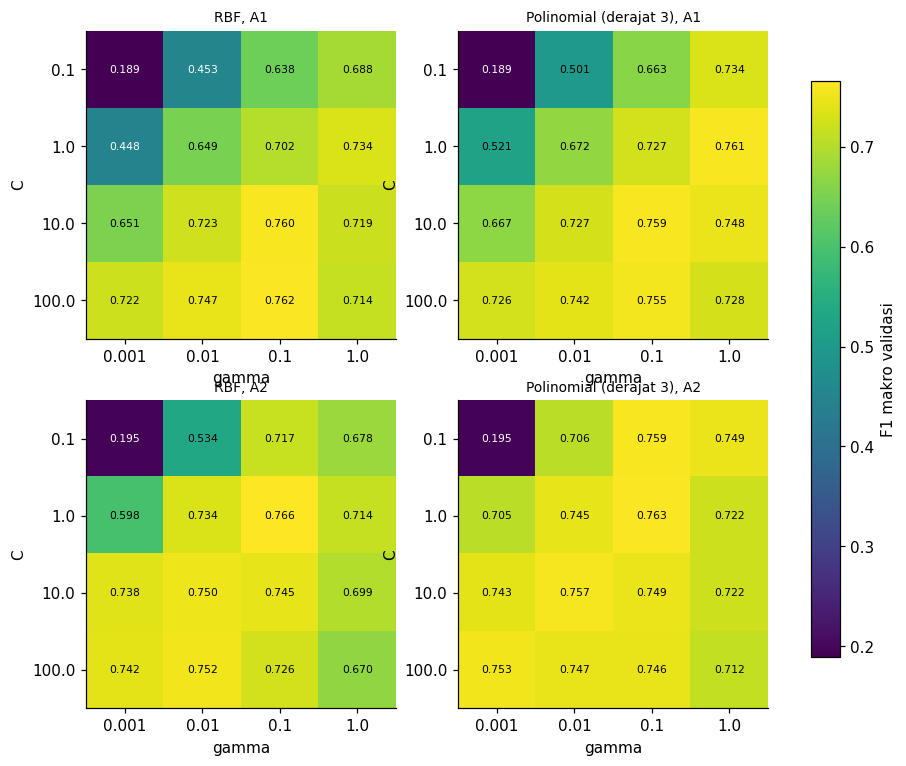

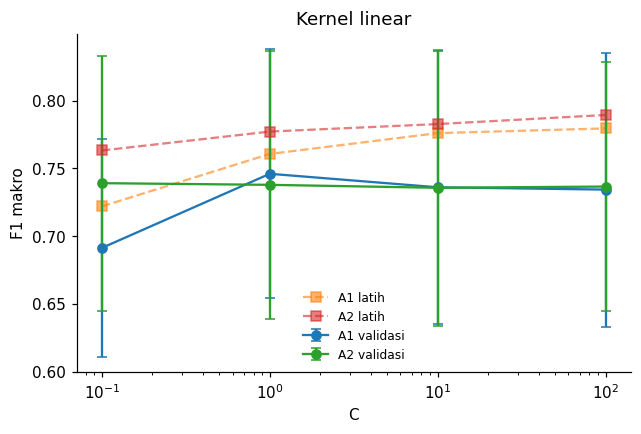

In [8]:
all_f1 = pd.concat([s["val_f1_mean"] for s in summaries.values()])
vmin, vmax = float(all_f1.min()), float(all_f1.max())

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (name, summary) in enumerate(summaries.items()):
    for col, kernel in enumerate(("rbf", "poly")):
        pivot = summary[summary["kernel"] == kernel].pivot(index="C", columns="gamma", values="val_f1_mean").sort_index()
        image = ev.plot_heatmap(axes[row, col], pivot, f"{KERNEL_LABEL[kernel]}, {name}", vmin, vmax, "gamma", "C")
fig.colorbar(image, ax=axes, shrink=0.85, label="F1 makro validasi")
save_figure(fig, "heatmap_c_gamma.png")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))
for name, summary in summaries.items():
    linear = summary[summary["kernel"] == "linear"].sort_values("C")
    ax.errorbar(linear["C"], linear["val_f1_mean"], yerr=linear["val_f1_sd"], marker="o", capsize=3, label=f"{name} validasi")
    ax.plot(linear["C"], linear["train_f1_mean"], marker="s", linestyle="--", alpha=0.6, label=f"{name} latih")
ax.set_xscale("log")
ax.set(xlabel="C", ylabel="F1 makro", title="Kernel linear")
ax.legend(frameon=False, fontsize=8)
save_figure(fig, "linear_c_curve.png")
plt.show()

##### 4.5 Sebaran skor lipatan tiap kernel

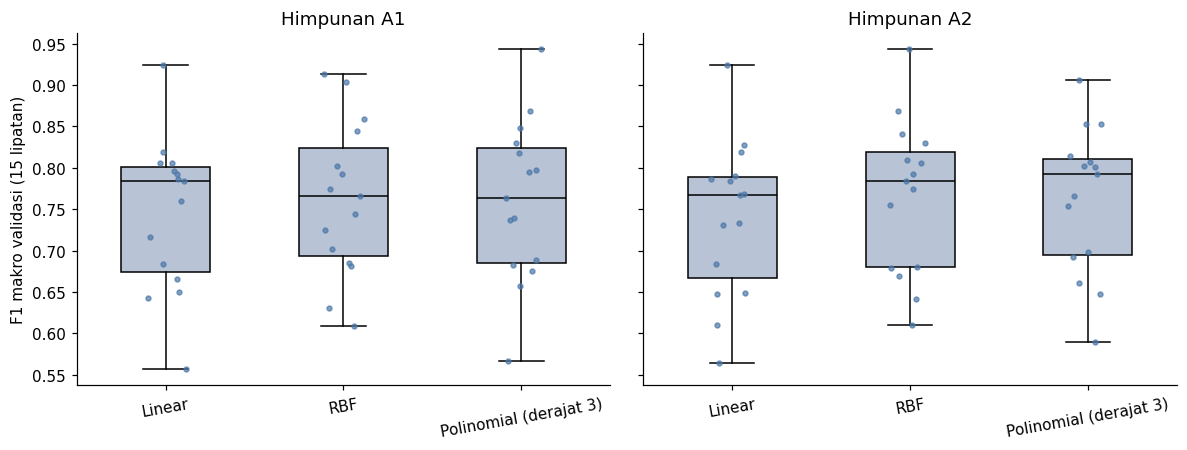

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, name in zip(axes, FEATURE_SETS):
    data, labels = [], []
    for kernel in KERNELS:
        config_id = int(best_per_kernel[(name, kernel)].name)
        scores = tuning_scores[name]
        data.append(scores.loc[scores["config_id"] == config_id, "val_macro_f1"].to_numpy())
        labels.append(KERNEL_LABEL[kernel])
    boxes = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops={"color": "black"})
    for patch in boxes["boxes"]:
        patch.set_facecolor("#B8C4D6")
    for i, values in enumerate(data, start=1):
        ax.scatter(np.full(len(values), i) + rng.uniform(-0.12, 0.12, len(values)), values, s=10, color="#4C78A8", alpha=0.7, zorder=3)
    ax.set_xticks(range(1, len(labels) + 1), labels, rotation=10)
    ax.set_title(f"Himpunan {name}")
axes[0].set_ylabel("F1 makro validasi (15 lipatan)")
fig.tight_layout()
save_figure(fig, "kernel_boxplot.png")
plt.show()

##### 4.6 Peringkat konfigurasi

In [10]:
for name, summary in summaries.items():
    ranked = summary.assign(_f1=summary["val_f1_mean"].round(4)).sort_values(["_f1", "n_support_total_mean"], ascending=[False, True], kind="stable")
    top = ranked[["kernel", "C", "gamma", "val_f1_mean", "val_f1_sd", "n_support_total_mean"]].head(10)
    save_table(top.round(4), f"top_configs_{name}")
    print(f"Sepuluh konfigurasi terbaik, himpunan {name}")
    display(top.round(4))

Sepuluh konfigurasi terbaik, himpunan A1


,kernel,C,gamma,val_f1_mean,val_f1_sd,n_support_total_mean
config_id,,,,,,
18,rbf,100.0,0.10,0.7623,0.0926,130.0667
27,poly,1.0,1.00,0.7607,0.0969,133.1333
14,rbf,10.0,0.10,0.7600,0.0858,154.0667
30,poly,10.0,0.10,0.7589,0.1004,140.7333
34,poly,100.0,0.10,0.7554,0.0923,123.7333
31,poly,10.0,1.00,0.7484,0.0882,120.4667
17,rbf,100.0,0.01,0.7473,0.0970,150.2667
1,linear,1.0,NaN,0.7461,0.0921,159.8000
33,poly,100.0,0.01,0.7417,0.1075,145.2667


Sepuluh konfigurasi terbaik, himpunan A2


,kernel,C,gamma,val_f1_mean,val_f1_sd,n_support_total_mean
config_id,,,,,,
10,rbf,1.0,0.100,0.7656,0.0927,163.8000
26,poly,1.0,0.100,0.7626,0.0879,139.4667
22,poly,0.1,0.100,0.7594,0.1015,179.2000
29,poly,10.0,0.010,0.7573,0.1071,147.6667
32,poly,100.0,0.001,0.7529,0.1006,147.5333
17,rbf,100.0,0.010,0.7523,0.0982,130.4667
13,rbf,10.0,0.010,0.7504,0.1069,153.0000
30,poly,10.0,0.100,0.7494,0.0795,123.6667
23,poly,0.1,1.000,0.7491,0.0738,124.8667


##### 4.7 Pemilihan konfigurasi

Pemenang adalah konfigurasi dengan rata-rata F1 makro validasi tertinggi. Jika sama pada empat desimal, dipilih konfigurasi dengan vektor pendukung lebih sedikit. Himpunan fitur mengikuti keputusan notebook 03.

In [11]:
best_config = {name: ev.select_best(summary, "n_support_total_mean") for name, summary in summaries.items()}
best_params = {name: ev.params_from_row(best_config[name], PARAM_COLUMNS) for name in FEATURE_SETS}

winner_table = pd.DataFrame(
    {
        name: {
            "kernel pemenang": KERNEL_LABEL[best_params[name]["kernel"]],
            "C": best_params[name]["C"],
            "gamma": best_params[name]["gamma"],
            "F1 makro validasi": best_config[name]["val_f1_mean"],
            "SD": best_config[name]["val_f1_sd"],
            "vektor pendukung": best_config[name]["n_support_total_mean"],
        }
        for name in FEATURE_SETS
    }
)
save_table(winner_table, "winner")
display(winner_table)
print("Himpunan fitur yang dievaluasi :", SELECTED_SET)
print("Parameter terpilih             :", best_params[SELECTED_SET])

,A1,A2
kernel pemenang,RBF,RBF
C,100,1
gamma,0.1,0.1
F1 makro validasi,0.762266,0.765627
SD,0.092614,0.092745
vektor pendukung,130.066667,163.8


Himpunan fitur yang dievaluasi : A1
Parameter terpilih             : {'kernel': 'rbf', 'C': 100, 'gamma': 0.1}


#### 5. Evaluasi Validasi Silang Model Terpilih

##### 5.1 Prediksi out-of-fold

In [12]:
oof = {}
for name in FEATURE_SETS:
    oof[name] = ev.cross_val_predictions(lambda n=name: make_model(best_params[n]), train, FEATURE_SETS[name])
    oof[name].to_csv(RESULTS_DIR / f"{PREFIX}_oof_{name}.csv", index=False)

oof_selected = oof[SELECTED_SET]
SELECTED_PARAMS = best_params[SELECTED_SET]
print("Himpunan fitur :", SELECTED_SET)
print("Parameter      :", SELECTED_PARAMS)
print("Baris OOF      :", len(oof_selected), f"({oof_selected['repeat'].nunique()} pengulangan)")

Himpunan fitur : A1
Parameter      : {'kernel': 'rbf', 'C': 100, 'gamma': 0.1}
Baris OOF      : 912 (3 pengulangan)


##### 5.2 Matriks konfusi

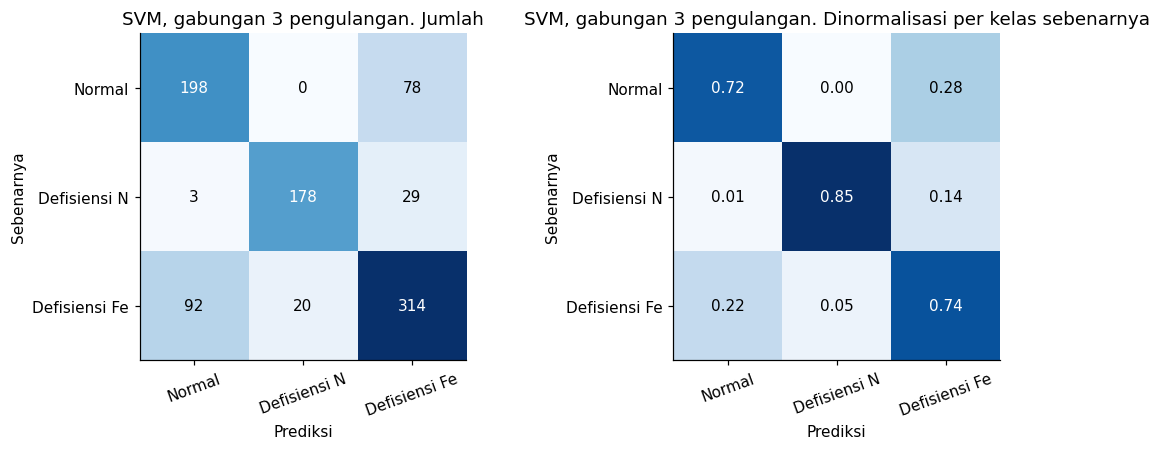

,Prediksi Normal,Prediksi Defisiensi N,Prediksi Defisiensi Fe
Sebenarnya Normal,66,0,26
Sebenarnya Defisiensi N,1,59,9
Sebenarnya Defisiensi Fe,30,6,104


In [13]:
pooled_counts = ev.confusion_counts(oof_selected["label"], oof_selected["pred"])
ev.plot_confusion(pooled_counts, title=f"{MODEL_LABEL}, gabungan 3 pengulangan.")
plt.gcf().tight_layout()
save_figure(plt.gcf(), "confusion_matrix.png")
plt.show()

confusion_table = pd.DataFrame(
    pooled_counts // oof_selected["repeat"].nunique(),
    index=[f"Sebenarnya {CLASS_LABEL_ID[c]}" for c in CLASSES],
    columns=[f"Prediksi {CLASS_LABEL_ID[c]}" for c in CLASSES],
)
save_table(confusion_table, "confusion_per_repeat")
display(confusion_table)

##### 5.3 Metrik per kelas dan skor lipatan

,precision,recall,f1,support
Normal,0.6758,0.7174,0.6960,276.0
Defisiensi N,0.8990,0.8476,0.8725,210.0
Defisiensi Fe,0.7458,0.7371,0.7414,426.0
Rata-rata makro,0.7735,0.7674,0.7700,912.0
Rata-rata berbobot,0.7599,0.7566,0.7579,912.0
Akurasi,NaN,NaN,0.7566,912.0


,mean,std,min,max
macro_f1,0.7623,0.0926,0.6091,0.9131
accuracy,0.7583,0.0915,0.5942,0.9130


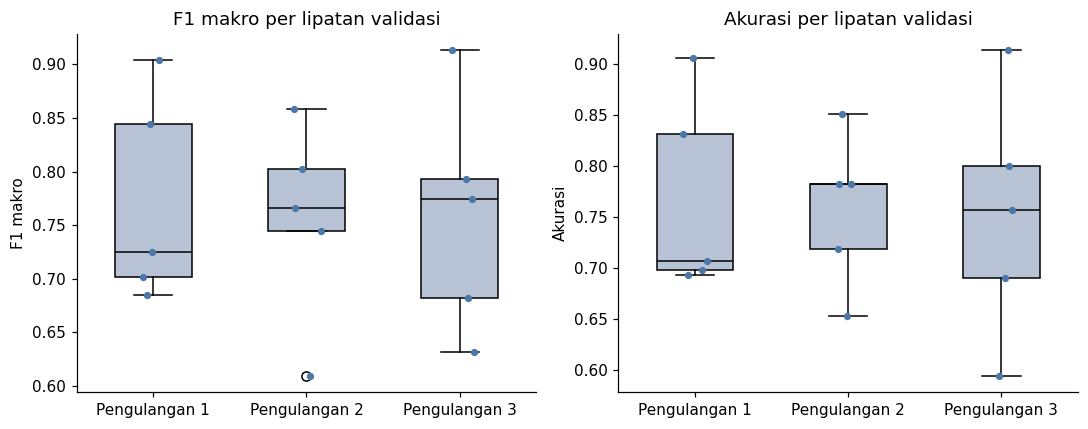

In [14]:
metric_table = ev.metrics_table(oof_selected["label"], oof_selected["pred"])
save_table(metric_table.round(4), "classification_metrics")
display(metric_table.round(4))

fold_table = ev.fold_scores(oof_selected)
fold_summary = fold_table[["macro_f1", "accuracy"]].agg(["mean", "std", "min", "max"]).T.round(4)
save_table(fold_summary, "fold_summary")
display(fold_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, title in zip(axes, ("macro_f1", "accuracy"), ("F1 makro", "Akurasi")):
    data = [fold_table.loc[fold_table["repeat"] == r, metric].to_numpy() for r in sorted(fold_table["repeat"].unique())]
    boxes = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops={"color": "black"})
    for patch in boxes["boxes"]:
        patch.set_facecolor("#B8C4D6")
    for i, values in enumerate(data, start=1):
        ax.scatter(np.full(len(values), i) + rng.uniform(-0.1, 0.1, len(values)), values, s=14, color="#4C78A8", zorder=3)
    ax.set_xticks(range(1, len(data) + 1), [f"Pengulangan {r}" for r in sorted(fold_table["repeat"].unique())])
    ax.set_ylabel(title)
    ax.set_title(f"{title} per lipatan validasi")
fig.tight_layout()
save_figure(fig, "fold_scores.png")
plt.show()

##### 5.4 Kurva ROC dan Precision-Recall

$$
\mathrm{TPR} = \frac{TP}{TP + FN}, \qquad \mathrm{FPR} = \frac{FP}{FP + TN}, \qquad \mathrm{AP} = \sum_{n} (R_n - R_{n-1})\, P_n
$$

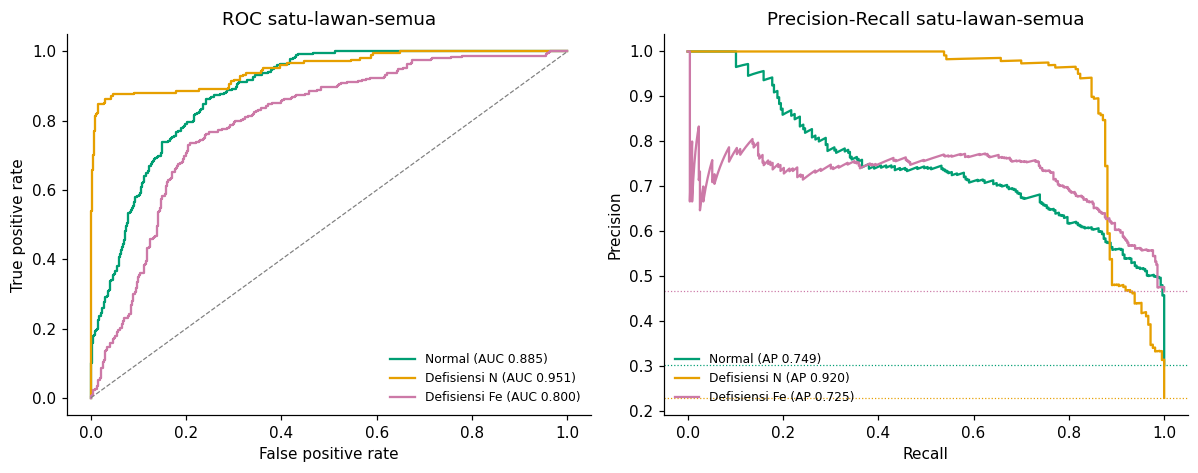

,AUC,AP,prevalensi
Normal,0.8848,0.7493,0.3026
Defisiensi N,0.9506,0.9201,0.2303
Defisiensi Fe,0.8001,0.7247,0.4671
Rata-rata makro,0.8785,0.7980,0.3333


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
curves = ev.plot_roc_pr(oof_selected, axes)
fig.tight_layout()
save_figure(fig, "roc_pr.png")
plt.show()

curve_table = pd.DataFrame({CLASS_LABEL_ID[k]: {"AUC": v["auc"], "AP": v["ap"], "prevalensi": v["prevalence"]} for k, v in curves.items()}).T
curve_table.loc["Rata-rata makro"] = curve_table.mean()
save_table(curve_table.round(4), "roc_pr_summary")
display(curve_table.round(4))

##### 5.5 Kurva pembelajaran

,train_files,train_f1,train_sd,val_f1,val_sd
fraction,,,,,
0.2,61.0,0.9176,0.0448,0.6813,0.0927
0.4,108.4,0.8486,0.0505,0.7199,0.0471
0.6,153.6,0.8307,0.0211,0.7405,0.0975
0.8,197.8,0.8395,0.0140,0.7651,0.0905
1.0,243.2,0.8265,0.0255,0.7719,0.0968


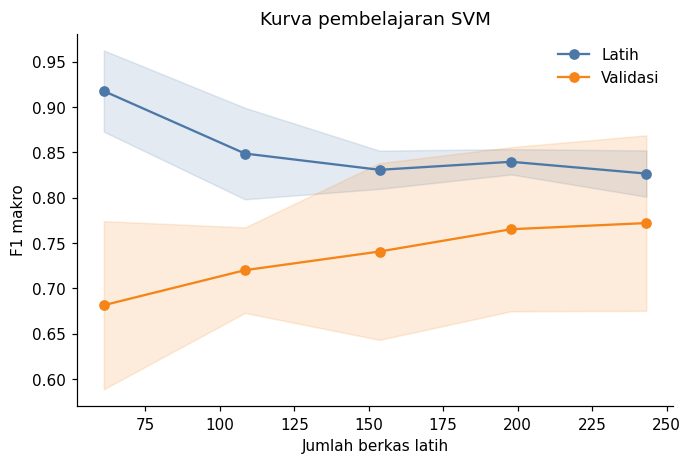

In [16]:
learning = ev.learning_curve(lambda: make_model(SELECTED_PARAMS), train, SELECTED_FEATURES, fractions=LEARNING_FRACTIONS, seed=SEED)
learning_summary = learning.groupby("fraction").agg(
    train_files=("train_files", "mean"),
    train_f1=("train_macro_f1", "mean"), train_sd=("train_macro_f1", "std"),
    val_f1=("val_macro_f1", "mean"), val_sd=("val_macro_f1", "std"),
)
save_table(learning_summary.round(4), "learning_curve")
display(learning_summary.round(4))

fig, ax = plt.subplots(figsize=(7, 4.4))
for column, sd, label, color in (("train_f1", "train_sd", "Latih", "#4C78A8"), ("val_f1", "val_sd", "Validasi", "#F58518")):
    ax.plot(learning_summary["train_files"], learning_summary[column], marker="o", color=color, label=label)
    ax.fill_between(learning_summary["train_files"], learning_summary[column] - learning_summary[sd], learning_summary[column] + learning_summary[sd], color=color, alpha=0.15)
ax.set(xlabel="Jumlah berkas latih", ylabel="F1 makro", title=f"Kurva pembelajaran {MODEL_LABEL}")
ax.legend(frameon=False)
save_figure(fig, "learning_curve.png")
plt.show()

##### 5.6 Pentingnya fitur (permutasi)

$$
\mathrm{PI}_j = F1_{\text{dasar}} - \frac{1}{R}\sum_{r=1}^{R} F1_{\text{acak}}^{(j, r)}
$$

,importance_mean,importance_sd
feature,,
Mean_R,0.4790,0.0960
Mean_G,0.1484,0.0921
Mean_B,0.1830,0.0533


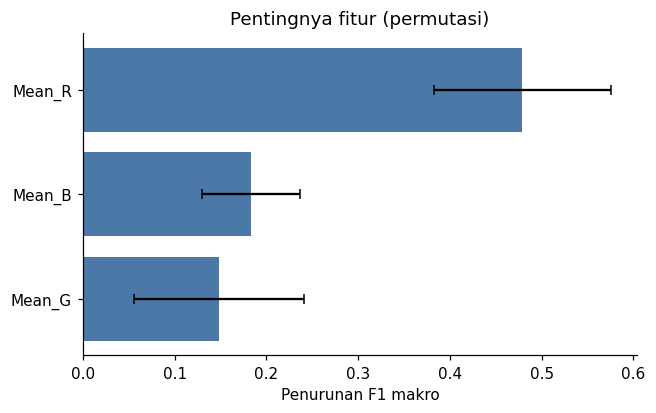

In [17]:
importance = ev.permutation_importance(lambda: make_model(SELECTED_PARAMS), train, SELECTED_FEATURES, n_repeats=PERMUTATION_REPEATS, seed=SEED)
save_table(importance.round(4), "permutation_importance")
display(importance.round(4))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ordered = importance.sort_values("importance_mean")
ax.barh(ordered.index, ordered["importance_mean"], xerr=ordered["importance_sd"], color="#4C78A8", capsize=3)
ax.set(xlabel="Penurunan F1 makro", title="Pentingnya fitur (permutasi)")
save_figure(fig, "permutation_importance.png")
plt.show()

##### 5.7 Galeri salah klasifikasi

,label,pred,jumlah
0,Defisiensi Fe,Defisiensi N,9
1,Defisiensi Fe,Normal,32
2,Defisiensi N,Defisiensi Fe,8
3,Defisiensi N,Normal,1
4,Normal,Defisiensi Fe,21


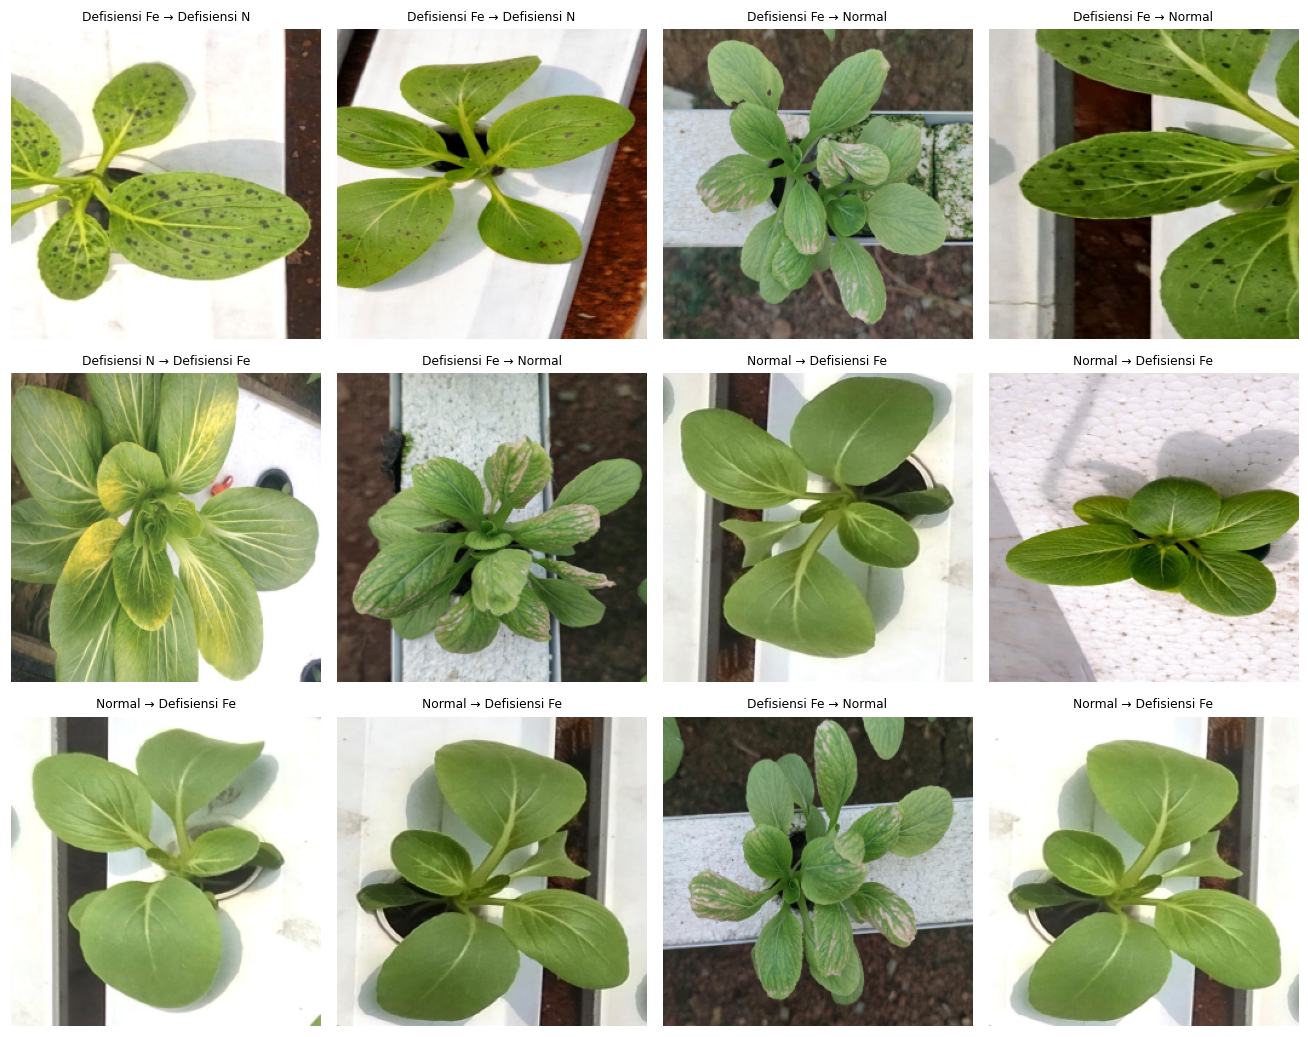

In [18]:
oof_selected = oof_selected.assign(correct=oof_selected["label"] == oof_selected["pred"])
errors = oof_selected[(oof_selected["repeat"] == 1) & (~oof_selected["correct"])]
error_pairs = errors.groupby(["label", "pred"]).size().rename("jumlah").reset_index()
error_pairs["label"] = error_pairs["label"].map(CLASS_LABEL_ID)
error_pairs["pred"] = error_pairs["pred"].map(CLASS_LABEL_ID)
save_table(error_pairs, "misclassified_pairs", index=False)
display(error_pairs)

fig = ev.plot_gallery(errors, RAW_DIR, max_items=GALLERY_SIZE, seed=SEED)
save_figure(fig, "misclassified_gallery.png")
plt.show()

##### 5.8 Interval kepercayaan bootstrap (resampling foto sumber)

$$
\hat{\theta}^{*(b)} = \theta\left(\{g_1^{*}, \dots, g_G^{*}\}\right), \qquad g_i^{*} \sim \mathrm{Uniform}(\mathcal{G}), \qquad \mathrm{CI}_{95\%} = \left[\hat{\theta}^{*}_{0{,}025},\ \hat{\theta}^{*}_{0{,}975}\right]
$$

,estimate,low,high
F1 makro,0.7700,0.6847,0.8398
Akurasi,0.7566,0.6753,0.8344
Recall Defisiensi N,0.8476,0.6520,0.9773
Recall Defisiensi Fe,0.7371,0.6307,0.8296
Recall Normal,0.7174,0.5625,0.8975


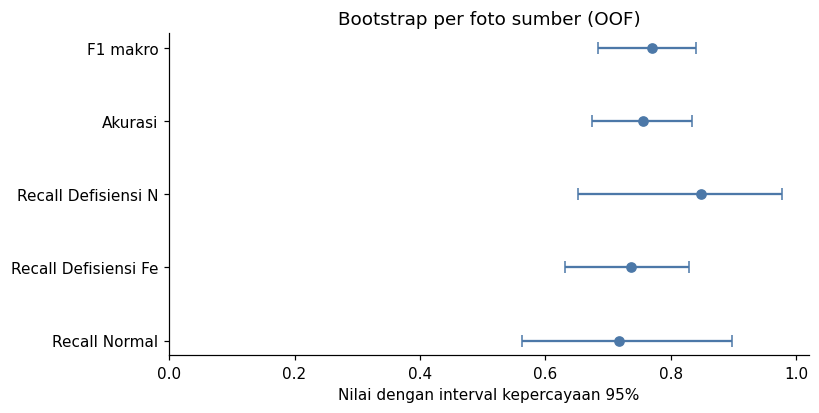

In [19]:
bootstrap_metrics = {
    "F1 makro": ev.fast_macro_f1,
    "Akurasi": ev.fast_accuracy,
    "Recall Defisiensi N": ev.fast_recall("n_deficiency"),
    "Recall Defisiensi Fe": ev.fast_recall("fe_deficiency"),
    "Recall Normal": ev.fast_recall("normal"),
}
bootstrap_rows = {name: ev.bootstrap_group_ci(oof_selected, metric, n_boot=N_BOOTSTRAP, seed=SEED) for name, metric in bootstrap_metrics.items()}
bootstrap_table = pd.DataFrame(bootstrap_rows).T[["estimate", "low", "high"]]
save_table(bootstrap_table.round(4), "bootstrap_ci")
display(bootstrap_table.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y_positions = np.arange(len(bootstrap_table))[::-1]
ax.errorbar(bootstrap_table["estimate"], y_positions, xerr=[bootstrap_table["estimate"] - bootstrap_table["low"], bootstrap_table["high"] - bootstrap_table["estimate"]], fmt="o", color="#4C78A8", capsize=4)
ax.set_yticks(y_positions, bootstrap_table.index)
ax.set(xlabel="Nilai dengan interval kepercayaan 95%", title="Bootstrap per foto sumber (OOF)")
ax.set_xlim(0, 1.02)
save_figure(fig, "bootstrap_ci.png")
plt.show()

##### 5.9 Perbandingan himpunan fitur A1 dan A2

In [20]:
comparison_rows = {}
for name in FEATURE_SETS:
    part = oof[name]
    folds = ev.fold_scores(part)
    comparison_rows[name] = {
        "parameter": str(best_params[name]),
        "F1 makro (rata-rata lipatan)": folds["macro_f1"].mean(),
        "SD lipatan": folds["macro_f1"].std(),
        "akurasi": folds["accuracy"].mean(),
        "recall Normal": ev.fast_recall("normal")(part["label"], part["pred"]),
        "recall Defisiensi N": ev.fast_recall("n_deficiency")(part["label"], part["pred"]),
        "recall Defisiensi Fe": ev.fast_recall("fe_deficiency")(part["label"], part["pred"]),
    }
feature_set_comparison = pd.DataFrame(comparison_rows)
save_table(feature_set_comparison, "feature_set_comparison")
display(feature_set_comparison)

,A1,A2
parameter,"{'kernel': 'rbf', 'C': 100, 'gamma': 0.1}","{'kernel': 'rbf', 'C': 1, 'gamma': 0.1}"
F1 makro (rata-rata lipatan),0.762266,0.765627
SD lipatan,0.092614,0.092745
akurasi,0.758344,0.764957
recall Normal,0.717391,0.793478
recall Defisiensi N,0.847619,0.852381
recall Defisiensi Fe,0.737089,0.680751


#### 6. Analisis Khusus SVM

##### 6.1 Vektor pendukung tiap kernel

,C,gamma,SV Normal,SV Defisiensi N,SV Defisiensi Fe,SV total,porsi dari data latih
kernel,,,,,,,
Linear,1,NaN,60,20,116,196,0.6447
RBF,100,0.1,47,17,96,160,0.5263
Polinomial (derajat 3),1,1.0,50,18,95,163,0.5362


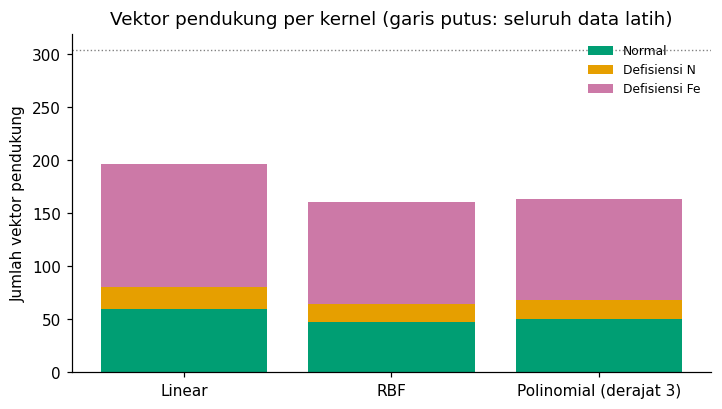

In [21]:
X_full = train[SELECTED_FEATURES].to_numpy(dtype=float)
y_full = train["label"].to_numpy()
class_totals = train["label"].value_counts().reindex(CLASSES)

kernel_models, sv_rows = {}, []
for kernel in KERNELS:
    best = best_per_kernel[(SELECTED_SET, kernel)]
    params = ev.params_from_row(best, PARAM_COLUMNS)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        kernel_models[kernel] = make_model(params).fit(X_full, y_full, SELECTED_FEATURES, CLASSES)
    counts = models.svm_support_counts(kernel_models[kernel])
    sv_rows.append(
        {
            "kernel": KERNEL_LABEL[kernel],
            "C": params["C"],
            "gamma": params["gamma"],
            **{f"SV {CLASS_LABEL_ID[c]}": counts[f"n_support_{c}"] for c in CLASSES},
            "SV total": counts["n_support_total"],
            "porsi dari data latih": counts["n_support_total"] / len(train),
        }
    )
sv_table = pd.DataFrame(sv_rows).set_index("kernel")
save_table(sv_table.round(4), "support_vectors")
display(sv_table.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4))
bottom = np.zeros(len(sv_table))
for c in CLASSES:
    values = sv_table[f"SV {CLASS_LABEL_ID[c]}"].to_numpy()
    ax.bar(sv_table.index, values, bottom=bottom, color=CLASS_COLORS[c], label=CLASS_LABEL_ID[c])
    bottom += values
ax.axhline(len(train), color="grey", linestyle=":", linewidth=0.9)
ax.set(ylabel="Jumlah vektor pendukung", title="Vektor pendukung per kernel (garis putus: seluruh data latih)")
ax.legend(frameon=False, fontsize=8)
save_figure(fig, "support_vectors.png")
plt.show()

##### 6.2 Wilayah keputusan dua dimensi

Dua fitur terpenting dari permutasi dipakai sebagai sumbu, fitur lain ditahan di nilai mediannya.

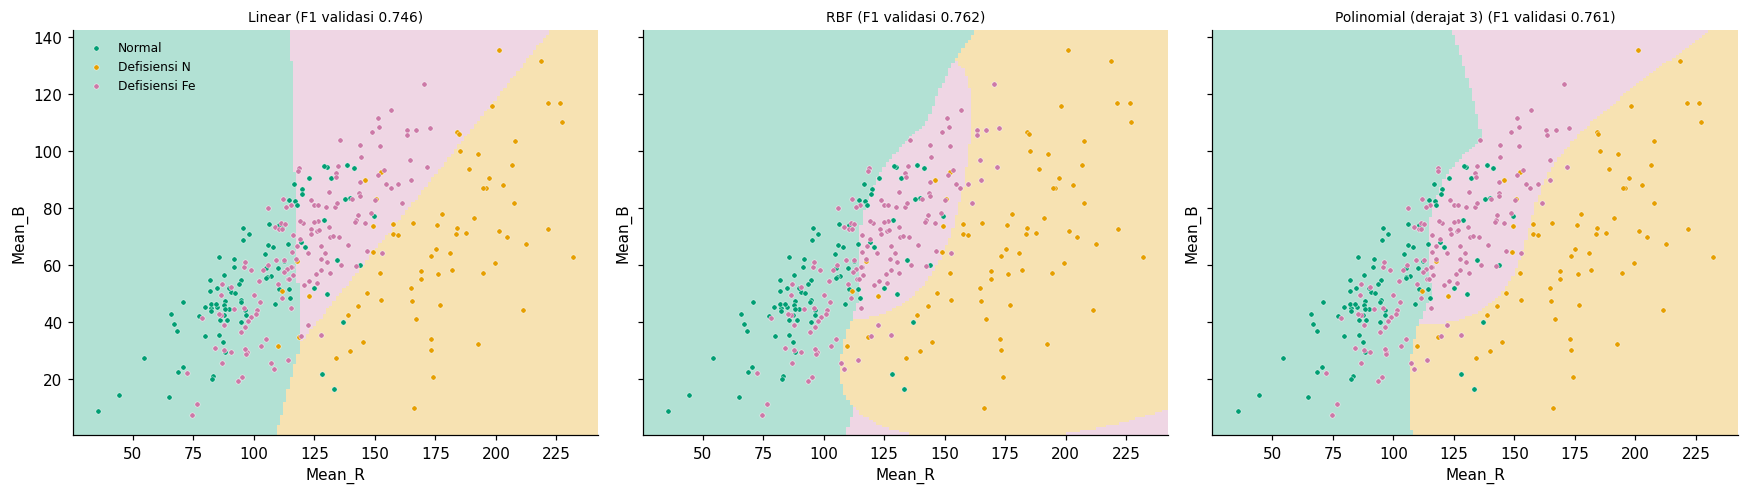

In [22]:
pair = ev.top_feature_pair(importance)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
for ax, kernel in zip(axes, KERNELS):
    ev.plot_decision_regions(kernel_models[kernel], train, SELECTED_FEATURES, pair, ax, title=f"{KERNEL_LABEL[kernel]} (F1 validasi {best_per_kernel[(SELECTED_SET, kernel)]['val_f1_mean']:.3f})")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, "decision_regions.png")
plt.show()

##### 6.3 Ringkasan khusus SVM

In [23]:
MODEL_SPECIFIC = {
    "winner_kernel": {name: best_params[name]["kernel"] for name in FEATURE_SETS},
    "kernel_best": {
        name: {
            kernel: {
                "C": as_float(best_per_kernel[(name, kernel)]["C"]),
                "gamma": as_float(best_per_kernel[(name, kernel)]["gamma"]),
                "val_macro_f1_mean": as_float(best_per_kernel[(name, kernel)]["val_f1_mean"]),
                "val_macro_f1_sd": as_float(best_per_kernel[(name, kernel)]["val_f1_sd"]),
            }
            for kernel in KERNELS
        }
        for name in FEATURE_SETS
    },
    "support_vectors_selected_set": {kernel: models.svm_support_counts(kernel_models[kernel]) for kernel in KERNELS},
    "decision_region_features": list(pair),
}
print(json.dumps(MODEL_SPECIFIC["winner_kernel"], indent=2))

{
  "A1": "rbf",
  "A2": "rbf"
}


#### 7. Model Akhir dan Waktu Komputasi

##### 7.1 Pelatihan pada seluruh data latih

In [24]:
X_selected = train[SELECTED_FEATURES].to_numpy(dtype=float)
y_selected = train["label"].to_numpy()

final_model = make_model(SELECTED_PARAMS).fit(X_selected, y_selected, SELECTED_FEATURES, CLASSES)
train_pred = final_model.predict(X_selected)

print("Parameter      :", SELECTED_PARAMS)
print("F1 makro latih :", round(ev.macro_f1(y_selected, train_pred), 4))
print("Akurasi latih  :", round(float(np.mean(train_pred == y_selected)), 4))

Parameter      : {'kernel': 'rbf', 'C': 100, 'gamma': 0.1}
F1 makro latih : 0.8132
Akurasi latih  : 0.8026


##### 7.2 Waktu komputasi

In [25]:
preprocessing_timing = pd.read_csv(TABLES_DIR / "01_timing_per_stage.csv", index_col=0)
PREPROCESSING_MS = float(preprocessing_timing.loc["total (tanpa baca berkas)", "rata-rata (ms)"])
PREPROCESSING_SD_MS = float(preprocessing_timing.loc["total (tanpa baca berkas)", "simpangan baku (ms)"])

fit_timing = ev.time_calls(lambda: make_model(SELECTED_PARAMS).fit(X_selected, y_selected, SELECTED_FEATURES, CLASSES), repeats=TRAIN_TIMING_REPEATS)
sample_rows = [X_selected[i : i + 1] for i in range(len(X_selected))]
predict_timing = ev.time_single_predictions(lambda i: final_model.predict(sample_rows[i]), len(X_selected), repeats=PREDICT_TIMING_REPEATS)

timing_rows = [
    {"pengukuran": "Praproses per citra", "nilai": PREPROCESSING_MS, "simpangan_baku": PREPROCESSING_SD_MS, "satuan": "ms"},
    {"pengukuran": "Pelatihan model akhir", "nilai": fit_timing["mean"], "simpangan_baku": fit_timing["sd"], "satuan": "detik"},
]
for name, seconds in tuning_seconds.items():
    timing_rows.append({"pengukuran": f"Penalaan {name} ({len(grid)} konfigurasi x 15 lipatan)", "nilai": seconds, "simpangan_baku": np.nan, "satuan": "detik"})
timing_rows.append({"pengukuran": "Prediksi per sampel", "nilai": predict_timing["mean_ms"], "simpangan_baku": predict_timing["sd_ms"], "satuan": "ms"})
timing_table = pd.DataFrame(timing_rows).set_index("pengukuran")
save_table(timing_table.round(4), "compute_time")
display(timing_table.round(4))

,nilai,simpangan_baku,satuan
pengukuran,,,
Praproses per citra,7.9350,6.1550,ms
Pelatihan model akhir,0.0052,0.0011,detik
Penalaan A1 (36 konfigurasi x 15 lipatan),6.0661,NaN,detik
Penalaan A2 (36 konfigurasi x 15 lipatan),10.7193,NaN,detik
Prediksi per sampel,0.1120,0.0087,ms


#### 8. Penyimpanan Hasil

##### 8.1 Berkas hasil dan model

In [26]:
artifact_path = MODELS_DIR / f"{PREFIX}_candidate.joblib"
joblib.dump(final_model.estimator, artifact_path)

results = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "model": PREFIX,
    "seed": SEED,
    "libraries": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "hardware": HARDWARE,
    "data": {"train_rows": int(len(train)), "train_groups": int(train["source_group"].nunique()), "fold_columns": list(ev.FOLD_COLUMNS)},
    "grid": {"configurations": int(len(grid))},
    "feature_set": {"selected": SELECTED_SET, "features": SELECTED_FEATURES, "source": "03_c45_results.json"},
    "best_config": {
        name: {
            "params": best_params[name],
            "val_macro_f1_mean": as_float(best_config[name]["val_f1_mean"]),
            "val_macro_f1_sd": as_float(best_config[name]["val_f1_sd"]),
            "train_macro_f1_mean": as_float(best_config[name]["train_f1_mean"]),
        }
        for name in FEATURE_SETS
    },
    "selected": {
        "feature_set": SELECTED_SET,
        "params": SELECTED_PARAMS,
        "oof_metrics": {
            "macro_f1_fold_mean": float(fold_table["macro_f1"].mean()),
            "macro_f1_fold_sd": float(fold_table["macro_f1"].std()),
            "accuracy_fold_mean": float(fold_table["accuracy"].mean()),
            "per_class_recall": {c: float(ev.fast_recall(c)(oof_selected["label"], oof_selected["pred"])) for c in CLASSES},
        },
        "bootstrap_95ci": {name: {k: float(v) for k, v in row.items() if k in ("estimate", "low", "high")} for name, row in bootstrap_rows.items()},
    },
    "model_specific": MODEL_SPECIFIC,
    "compute": {
        "preprocessing_ms_per_image": {"mean": PREPROCESSING_MS, "sd": PREPROCESSING_SD_MS},
        "final_train_seconds": fit_timing,
        "tuning_seconds": tuning_seconds,
        "predict_ms_per_sample": predict_timing,
    },
    "artifacts": {"model": str(artifact_path.relative_to(ML_DIR)), "oof": [f"reports/results/{PREFIX}_oof_{name}.csv" for name in FEATURE_SETS]},
}
results_path = RESULTS_DIR / f"{PREFIX}_results.json"
results_path.write_text(json.dumps(results, indent=2, default=str), encoding="utf-8")
print("Disimpan :", results_path)
print("Disimpan :", artifact_path, f"({artifact_path.stat().st_size} byte)")

Disimpan : D:\LARAGON\www\nutrify\ml\reports\results\04_svm_results.json
Disimpan : D:\LARAGON\www\nutrify\ml\models\candidates\04_svm_candidate.joblib (12050 byte)


##### 8.2 Ringkasan akhir

In [27]:
final_summary = pd.DataFrame(
    [
        ("Himpunan fitur", SELECTED_SET),
        ("Parameter", str(SELECTED_PARAMS)),
        ("F1 makro validasi (rata-rata 15 lipatan)", round(results["selected"]["oof_metrics"]["macro_f1_fold_mean"], 4)),
        ("SD F1 makro lipatan", round(results["selected"]["oof_metrics"]["macro_f1_fold_sd"], 4)),
        ("Recall Normal", round(results["selected"]["oof_metrics"]["per_class_recall"]["normal"], 4)),
        ("Recall Defisiensi N", round(results["selected"]["oof_metrics"]["per_class_recall"]["n_deficiency"], 4)),
        ("Recall Defisiensi Fe", round(results["selected"]["oof_metrics"]["per_class_recall"]["fe_deficiency"], 4)),
        ("Prediksi per sampel (ms)", round(predict_timing["mean_ms"], 4)),
    ],
    columns=["item", "nilai"],
)
save_table(final_summary, "final_summary", index=False)
display(final_summary)

,item,nilai
0,Himpunan fitur,A1
1,Parameter,"{'kernel': 'rbf', 'C': 100, 'gamma': 0.1}"
2,F1 makro validasi (rata-rata 15 lipatan),0.7623
3,SD F1 makro lipatan,0.0926
4,Recall Normal,0.7174
5,Recall Defisiensi N,0.8476
6,Recall Defisiensi Fe,0.7371
7,Prediksi per sampel (ms),0.112
